# Retail Sales & Profitability Analytics — MySQL + Python

**Level:** Basic to intermediate, with selected advanced SQL patterns  
**Dataset:** Sample Superstore (Orders, People, Returns)  
**Workflow:** CSV → MySQL `LOAD DATA LOCAL INFILE` → SQL business queries → Python MySQL Connector → Pandas DataFrames → Matplotlib visualizations.

## Learning objectives
1. Understand transaction-level data and order-level counting.
2. Create and validate a MySQL database.
3. Connect Jupyter Notebook to MySQL securely.
4. Execute at least 17 SQL business queries.
5. Convert query results into DataFrames and visualize every result.
6. Interpret insights without confusing correlation with causation.

> Before running this notebook, run `sql/01_create_load_validate.sql` after updating its three CSV paths. Confirm the three tables exist in the `retail_analytics` database. Do not put your database password into a notebook you plan to publish.


## 0. Install required packages

Run this once in a Jupyter cell if packages are missing. If using Anaconda, install them into the same environment as your notebook kernel.

In [ ]:
# Uncomment and run if these packages are not installed:
# %pip install mysql-connector-python pandas matplotlib openpyxl

## 1. Imports and display settings

In [2]:
import os
import getpass
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


## 2. Connect Jupyter to MySQL

Use environment variables when available, otherwise enter your password privately when prompted. Update the username/host if your MySQL setup differs.

In [3]:
DB_CONFIG = {
    "host": os.getenv("MYSQL_HOST", "localhost"),
    "user": os.getenv("MYSQL_USER", "root"),
    "password": os.getenv("ashish") or getpass.getpass("MySQL password: "),
    "database": "retail_analytics",
    "port": int(os.getenv("MYSQL_PORT", "3306")),
}

connection = mysql.connector.connect(**DB_CONFIG)
print("Connected:", connection.is_connected())

# Quick check
with connection.cursor() as cursor:
    cursor.execute("SELECT DATABASE(), VERSION()")
    print("Database, MySQL version:", cursor.fetchone())


MySQL password:  ········


Connected: True
Database, MySQL version: ('retail_analytics', '10.4.32-MariaDB')


## 3. Inspect tables and validate the imported data

In [5]:
def read_sql_df(query, params=None):
    """Run a SELECT query on MySQL and return the result as a Pandas DataFrame."""
    return pd.read_sql(query, connection, params=params)

table_check = read_sql_df("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = DATABASE()
ORDER BY table_name
""")
display(table_check)

validation = read_sql_df("""
SELECT
    COUNT(*) AS transaction_lines,
    COUNT(DISTINCT order_id) AS distinct_orders,
    COUNT(DISTINCT customer_id) AS distinct_customers,
    COUNT(DISTINCT product_id) AS distinct_products,
    SUM(sales) AS total_sales,
    SUM(profit) AS total_profit,
    SUM(quantity) AS total_quantity,
    SUM(profit) / NULLIF(SUM(sales), 0) AS profit_margin
FROM orders
""")
display(validation)


C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


,table_name
0,orders
1,people
2,returns


C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


,transaction_lines,distinct_orders,distinct_customers,distinct_products,total_sales,total_profit,total_quantity,profit_margin
0,10194,5111,804,1862,2326534.52,292297.46,38654.0,0.125636


## 4. Data quality checks and Python-side cleaning

We keep the raw SQL table intact, run validation checks, then create a Python analysis copy. Never silently delete valid negative-profit rows. We only standardize types and flag issues for investigation.

In [6]:
quality_checks = {
    "missing values by column": read_sql_df("""
        SELECT
            SUM(row_id IS NULL) AS row_id_nulls,
            SUM(order_id IS NULL) AS order_id_nulls,
            SUM(order_date IS NULL) AS order_date_nulls,
            SUM(sales IS NULL) AS sales_nulls,
            SUM(profit IS NULL) AS profit_nulls,
            SUM(quantity IS NULL) AS quantity_nulls
        FROM orders
    """),
    "duplicate Row IDs": read_sql_df("""
        SELECT row_id, COUNT(*) AS n
        FROM orders GROUP BY row_id HAVING COUNT(*) > 1
    """),
    "invalid shipping dates": read_sql_df("""
        SELECT COUNT(*) AS ship_before_order
        FROM orders WHERE ship_date < order_date
    """),
    "discount range": read_sql_df("""
        SELECT MIN(discount) AS min_discount, MAX(discount) AS max_discount
        FROM orders
    """),
    "negative profit rows": read_sql_df("""
        SELECT COUNT(*) AS negative_profit_lines
        FROM orders WHERE profit < 0
    """),
}
for label, result in quality_checks.items():
    print("\\n", label)
    display(result)

# Build a cleaned/typed analysis copy from SQL.
df_orders = read_sql_df("""
SELECT row_id, order_id, order_date, ship_date, ship_mode, customer_id,
       customer_name, segment, country_region, city, state_province,
       postal_code, region, product_id, category, sub_category, product_name,
       sales, quantity, discount, profit
FROM orders
""")

df_orders["order_date"] = pd.to_datetime(df_orders["order_date"], errors="coerce")
df_orders["ship_date"] = pd.to_datetime(df_orders["ship_date"], errors="coerce")
for col in ["sales", "profit", "discount"]:
    df_orders[col] = pd.to_numeric(df_orders[col], errors="coerce")
df_orders["quantity"] = pd.to_numeric(df_orders["quantity"], errors="coerce").astype("Int64")
df_orders["ship_days"] = (df_orders["ship_date"] - df_orders["order_date"]).dt.days
df_orders["order_month"] = df_orders["order_date"].dt.to_period("M").dt.to_timestamp()
df_orders["profit_margin_line"] = np.where(
    df_orders["sales"].ne(0),
    df_orders["profit"] / df_orders["sales"],
    np.nan
)

print("Python analysis copy shape:", df_orders.shape)
display(df_orders.head())
print("Missing values after type conversion:")
display(df_orders.isna().sum().sort_values(ascending=False).head(10))


\n missing values by column


C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)
C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


,row_id_nulls,order_id_nulls,order_date_nulls,sales_nulls,profit_nulls,quantity_nulls
0,0.0,0.0,0.0,0.0,0.0,0.0


\n duplicate Row IDs


,row_id,n


...

C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


Python analysis copy shape: (10194, 24)


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country_region,city,state_province,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,ship_days,order_month,profit_margin_line
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.2,5.55,4,2023-01-01,0.337386
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,0.8,-5.49,4,2023-01-01,-1.550847
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.78,3,0.2,4.27,4,2023-01-01,0.362479
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.74,3,0.2,-64.77,4,2023-01-01,-0.237479
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,0.2,4.88,7,2023-01-01,0.249744


Missing values after type conversion:


row_id            0
order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_id       0
customer_name     0
segment           0
country_region    0
city              0
dtype: int64

## 5. SQL query library — 17 business questions

Each query is executed in MySQL, its result is loaded into a Pandas DataFrame, displayed, and visualized. The SQL aggregation is done in MySQL; Python is used for retrieval and plotting.

In [7]:
QUERIES = {
    'Q01': ('Q01 — Overall KPIs', 'SELECT\n    SUM(sales) AS total_sales,\n    SUM(profit) AS total_profit,\n    COUNT(DISTINCT order_id) AS distinct_orders,\n    COUNT(DISTINCT customer_id) AS distinct_customers,\n    SUM(quantity) AS units_sold,\n    SUM(profit) / NULLIF(SUM(sales), 0) AS profit_margin\nFROM orders', 'kpi'),
    'Q02': ('Q02 — Monthly sales trend', "SELECT DATE_FORMAT(order_date, '%Y-%m-01') AS order_month,\n       SUM(sales) AS total_sales, SUM(profit) AS total_profit\nFROM orders\nGROUP BY DATE_FORMAT(order_date, '%Y-%m-01')\nORDER BY order_month", 'line_sales'),
    'Q03': ('Q03 — Sales by category', 'SELECT category, SUM(sales) AS total_sales, SUM(profit) AS total_profit\nFROM orders GROUP BY category ORDER BY total_sales DESC', 'bar_sales'),
    'Q04': ('Q04 — Profit by sub-category (lowest first)', 'SELECT sub_category, SUM(profit) AS total_profit, SUM(sales) AS total_sales\nFROM orders GROUP BY sub_category ORDER BY total_profit ASC', 'bar_profit'),
    'Q05': ('Q05 — Sales by region', 'SELECT region, SUM(sales) AS total_sales, SUM(profit) AS total_profit\nFROM orders GROUP BY region ORDER BY total_sales DESC', 'bar_sales'),
    'Q06': ('Q06 — Sales by customer segment', 'SELECT segment, SUM(sales) AS total_sales, SUM(profit) AS total_profit,\n       COUNT(DISTINCT customer_id) AS customers\nFROM orders GROUP BY segment ORDER BY total_sales DESC', 'bar_sales'),
    'Q07': ('Q07 — Top 10 products by profit', 'SELECT product_id, product_name, SUM(profit) AS total_profit, SUM(sales) AS total_sales\nFROM orders GROUP BY product_id, product_name\nORDER BY total_profit DESC LIMIT 10', 'bar_product_profit'),
    'Q08': ('Q08 — Bottom 10 products by profit', 'SELECT product_id, product_name, SUM(profit) AS total_profit, SUM(sales) AS total_sales\nFROM orders GROUP BY product_id, product_name\nORDER BY total_profit ASC LIMIT 10', 'bar_product_profit'),
    'Q09': ('Q09 — Discount bands and profitability', "SELECT\n    CASE\n      WHEN discount = 0 THEN '0% (no discount)'\n      WHEN discount <= 0.10 THEN '>0%–10%'\n      WHEN discount <= 0.20 THEN '>10%–20%'\n      WHEN discount <= 0.30 THEN '>20%–30%'\n      ELSE '>30%'\n    END AS discount_band,\n    COUNT(*) AS transaction_lines,\n    SUM(sales) AS total_sales,\n    SUM(profit) AS total_profit,\n    SUM(profit) / NULLIF(SUM(sales), 0) AS profit_margin\nFROM orders\nGROUP BY discount_band\nORDER BY MIN(discount)", 'bar_profit'),
    'Q10': ('Q10 — Sales by ship mode', 'SELECT ship_mode, SUM(sales) AS total_sales, SUM(profit) AS total_profit,\n       AVG(DATEDIFF(ship_date, order_date)) AS avg_ship_days\nFROM orders GROUP BY ship_mode ORDER BY total_sales DESC', 'bar_sales'),
    'Q11': ('Q11 — Shipping duration distribution', 'SELECT DATEDIFF(ship_date, order_date) AS ship_days,\n       COUNT(*) AS transaction_lines\nFROM orders\nGROUP BY DATEDIFF(ship_date, order_date)\nORDER BY ship_days', 'hist_ship'),
    'Q12': ('Q12 — Returned order rate by region', "WITH order_region AS (\n    SELECT order_id, MAX(region) AS region FROM orders GROUP BY order_id\n),\nreturned_orders AS (\n    SELECT DISTINCT order_id FROM returns WHERE LOWER(TRIM(returned)) = 'yes'\n)\nSELECT o.region, COUNT(*) AS distinct_orders,\n       COUNT(r.order_id) AS returned_orders,\n       COUNT(r.order_id) / COUNT(*) AS returned_order_rate\nFROM order_region o\nLEFT JOIN returned_orders r ON o.order_id = r.order_id\nGROUP BY o.region ORDER BY returned_order_rate DESC", 'bar_rate'),
    'Q13': ('Q13 — Monthly profit margin', "SELECT DATE_FORMAT(order_date, '%Y-%m-01') AS order_month,\n       SUM(sales) AS total_sales, SUM(profit) AS total_profit,\n       SUM(profit) / NULLIF(SUM(sales), 0) AS profit_margin\nFROM orders\nGROUP BY DATE_FORMAT(order_date, '%Y-%m-01')\nORDER BY order_month", 'line_margin'),
    'Q14': ('Q14 — Top 10 customers by sales', 'SELECT customer_id, customer_name, SUM(sales) AS total_sales,\n       SUM(profit) AS total_profit, COUNT(DISTINCT order_id) AS distinct_orders\nFROM orders\nGROUP BY customer_id, customer_name\nORDER BY total_sales DESC LIMIT 10', 'bar_customer'),
    'Q15': ('Q15 — Category sales vs profit', 'SELECT category, SUM(sales) AS total_sales, SUM(profit) AS total_profit\nFROM orders GROUP BY category ORDER BY total_sales DESC', 'grouped_category'),
    'Q16': ('Q16 — Quantity sold by category', 'SELECT category, SUM(quantity) AS units_sold\nFROM orders GROUP BY category ORDER BY units_sold DESC', 'bar_quantity'),
    'Q17': ('Q17 — Top 10 states by sales', 'SELECT state_province, SUM(sales) AS total_sales, SUM(profit) AS total_profit\nFROM orders GROUP BY state_province ORDER BY total_sales DESC LIMIT 10', 'bar_state')
}

print(f"Loaded {len(QUERIES)} SQL business queries.")

Loaded 17 SQL business queries.


### 5A. Reusable query runner

The `query_results` dictionary stores each query's DataFrame so we can reuse the same output for charts, exports, and written analysis.

In [8]:
query_results = {}

for query_id, (title, sql, chart_type) in QUERIES.items():
    print(f"\\n{title}")
    result_df = read_sql_df(sql)
    query_results[query_id] = result_df
    display(result_df.head(15))
    print("Rows returned:", len(result_df))


\nQ01 — Overall KPIs


C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


,total_sales,total_profit,distinct_orders,distinct_customers,units_sold,profit_margin
0,2326534.52,292297.46,5111,804,38654.0,0.125636


Rows returned: 1
\nQ02 — Monthly sales trend


C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


...

,category,units_sold
0,Office Supplies,23268.0
1,Furniture,8369.0
2,Technology,7017.0


Rows returned: 3
\nQ17 — Top 10 states by sales


C:\Users\dell\AppData\Local\Temp\ipykernel_27828\1473165078.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, connection, params=params)


,state_province,total_sales,total_profit
0,California,457687.68,76381.57
1,New York,310876.20,74038.63
2,Texas,170187.98,-25729.29
3,Washington,138641.29,33402.70
4,Pennsylvania,116512.02,-15560.06
5,Florida,89473.73,-3399.25
6,Illinois,80166.16,-12607.89
7,Ohio,78258.21,-16971.37
8,Michigan,76269.61,24463.15
9,Virginia,70636.72,18597.99


Rows returned: 10


## 6. Visualize all 17 query results with Matplotlib

These charts are exploratory. For discount and return analysis, describe associations and rates carefully; do not claim causation without further testing.

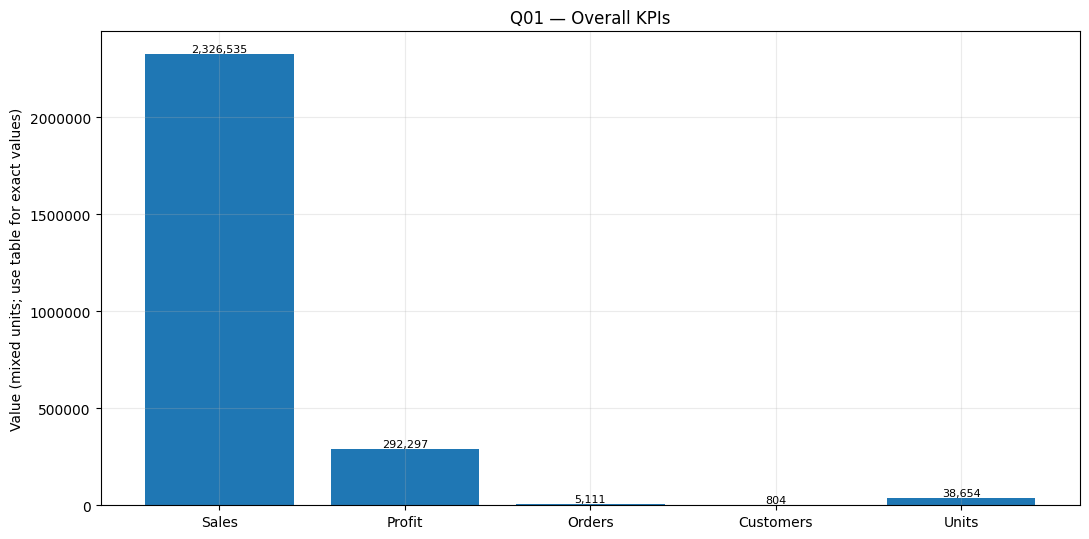

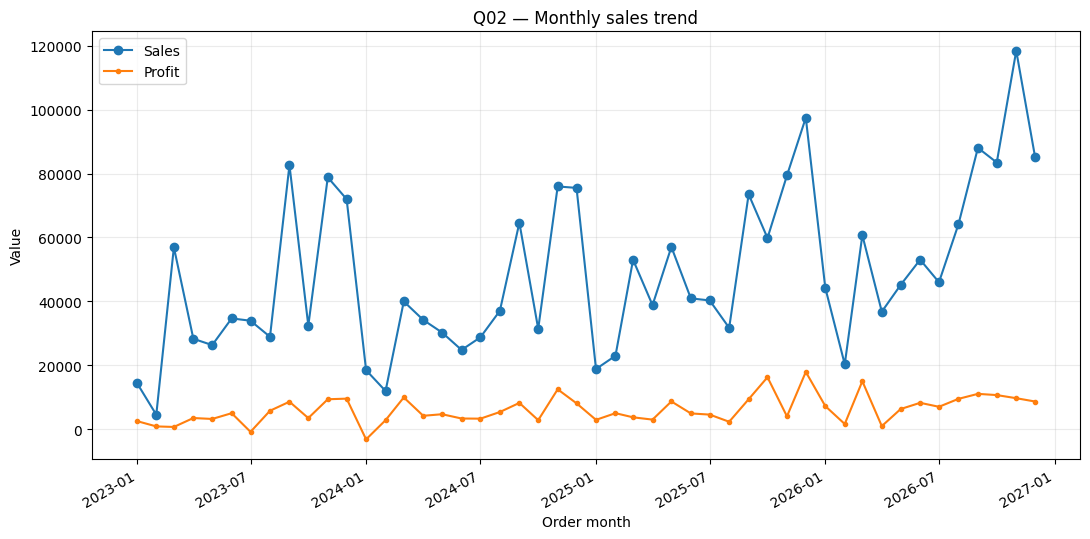

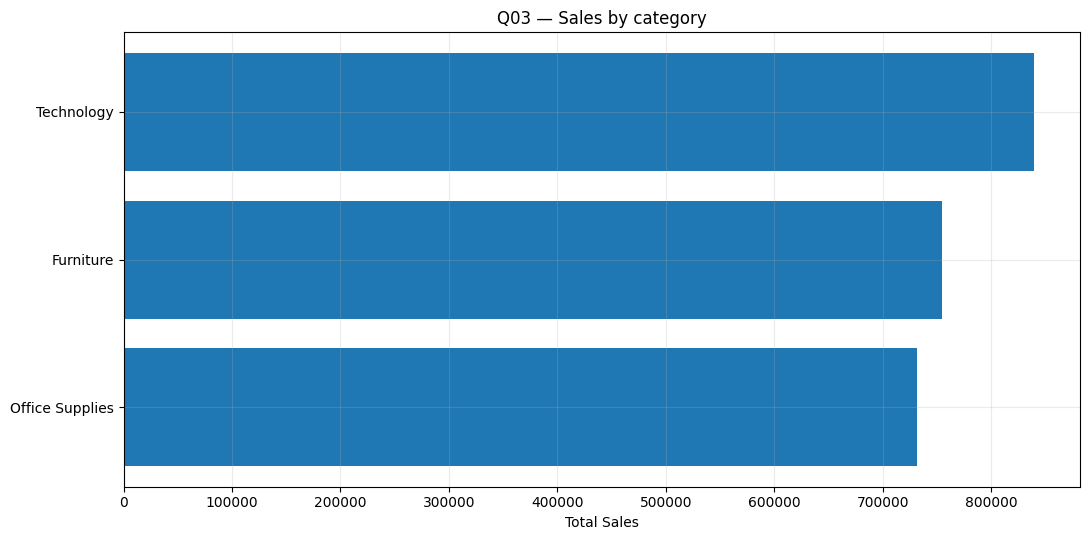

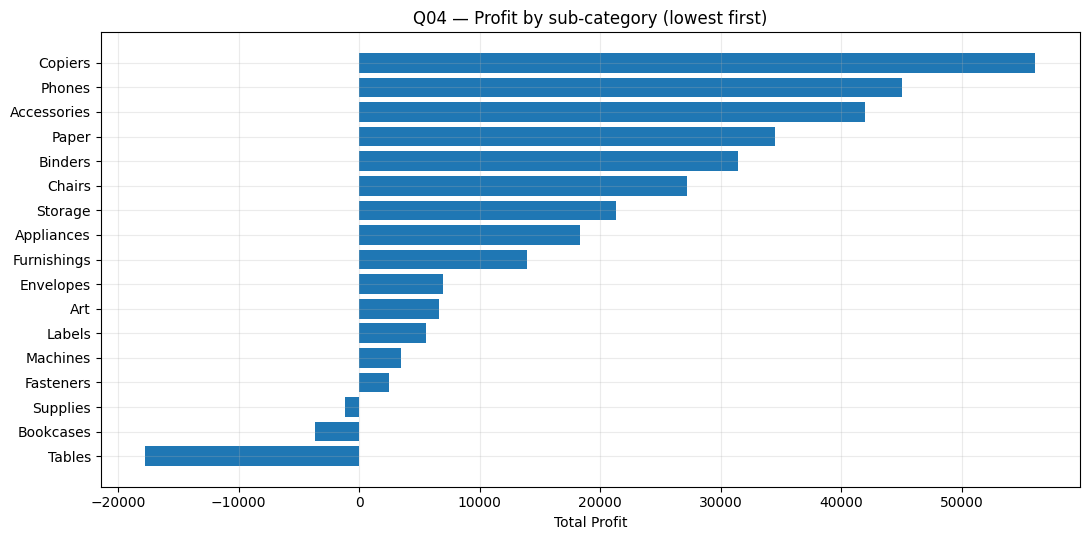

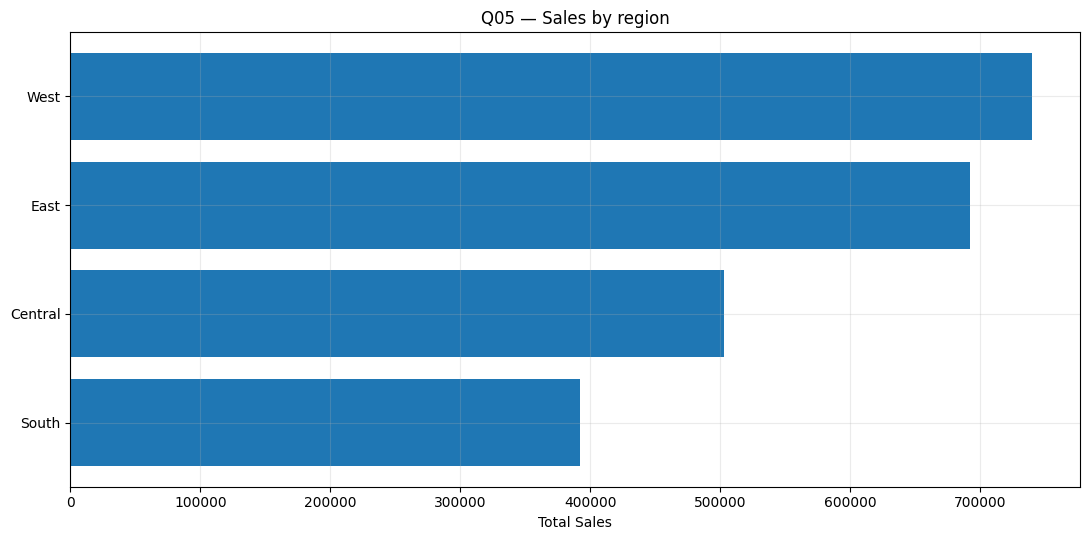

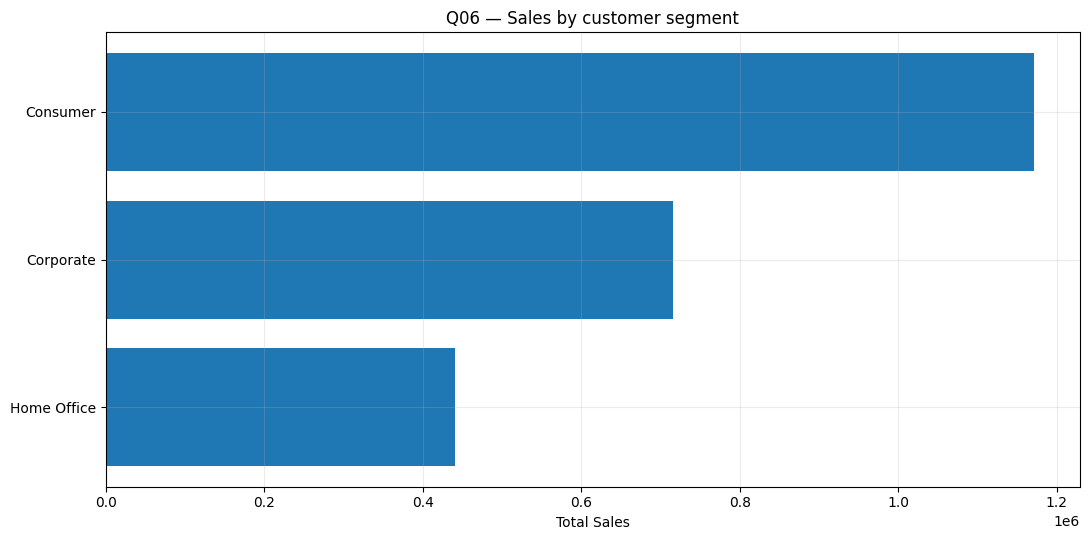

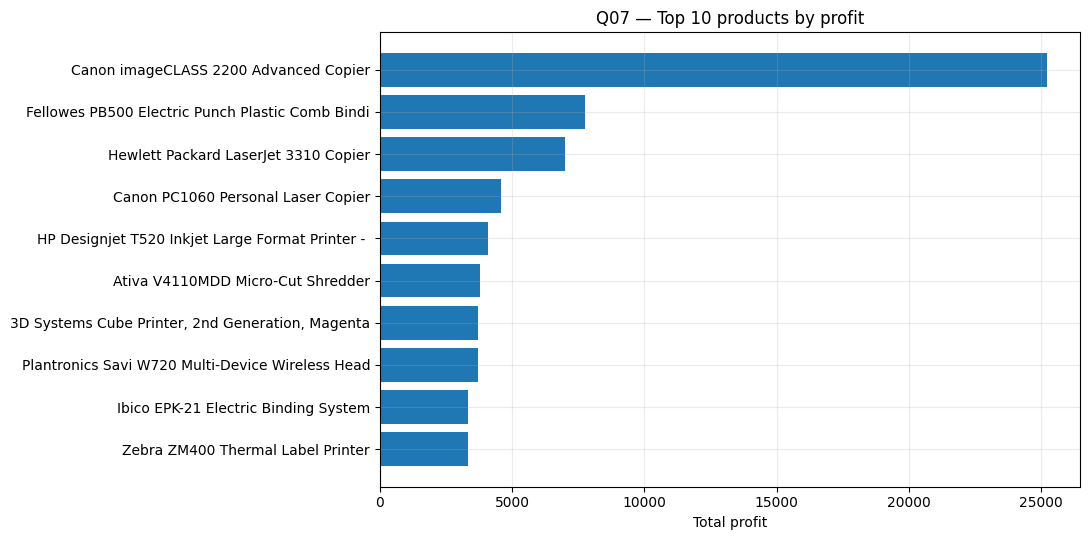

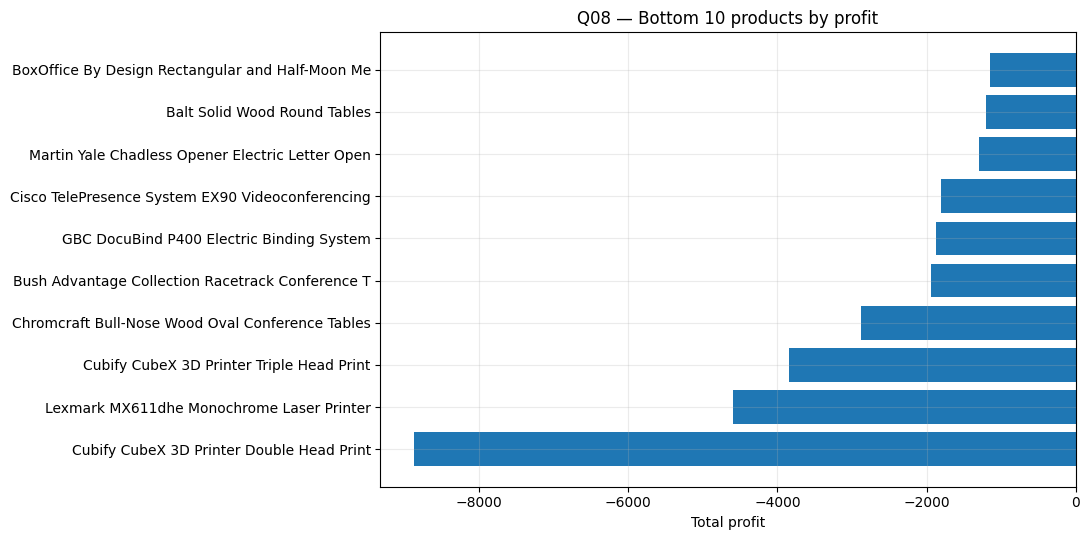

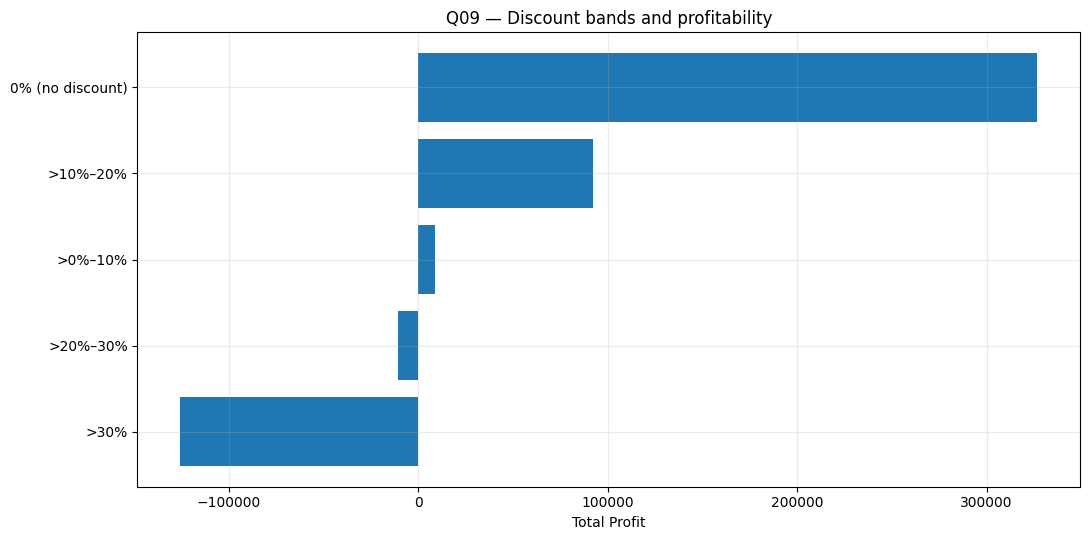

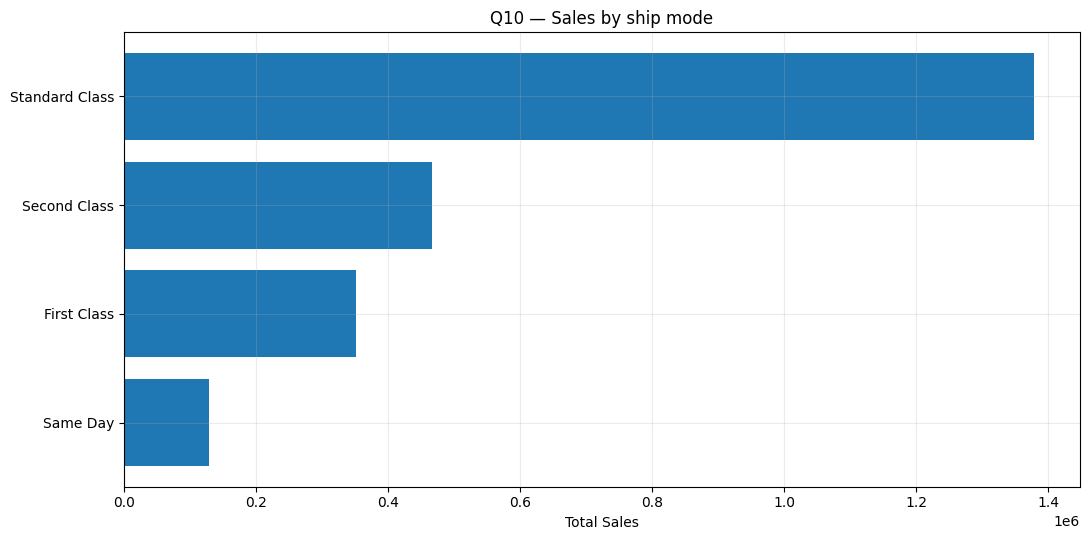

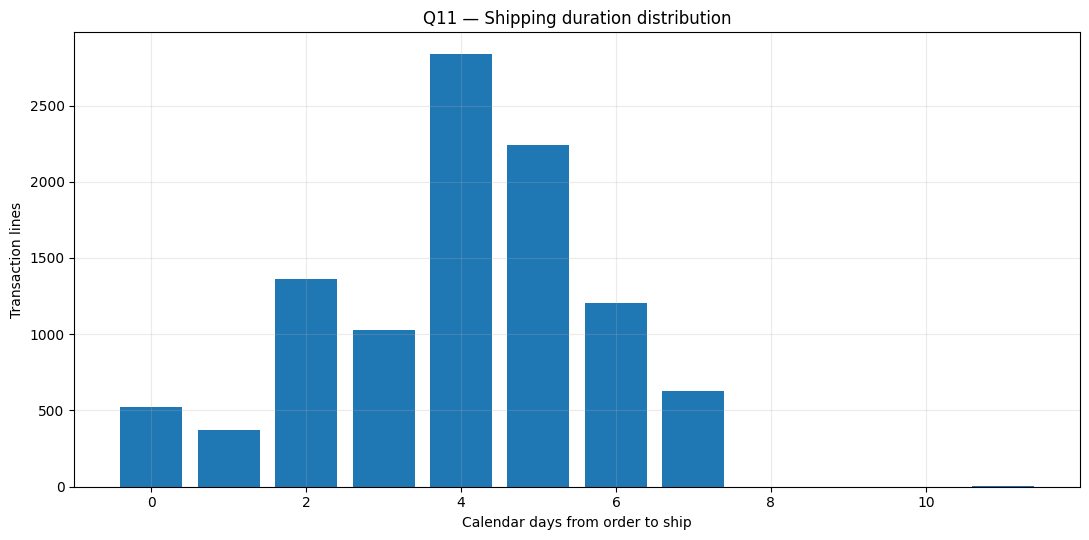

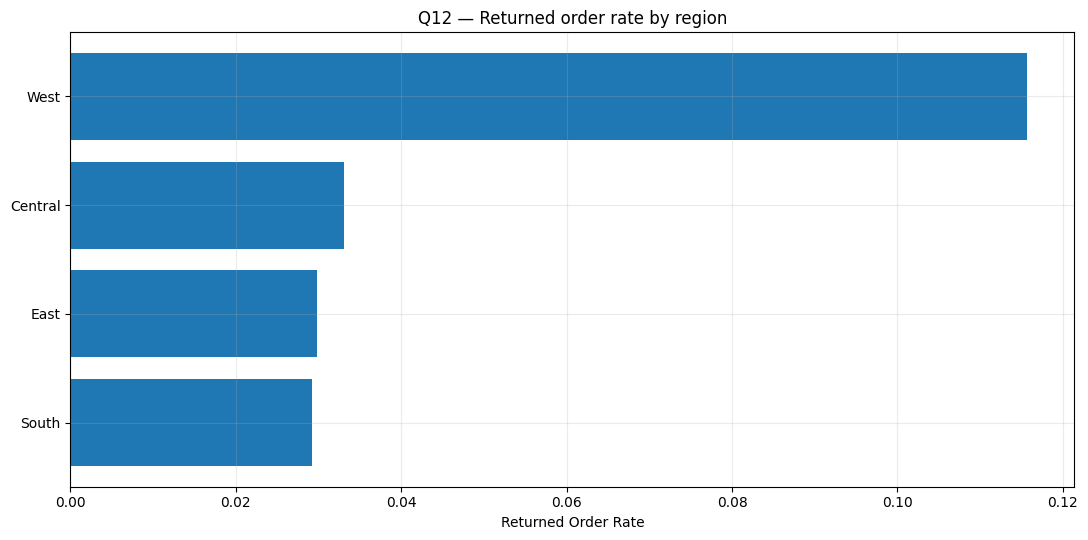

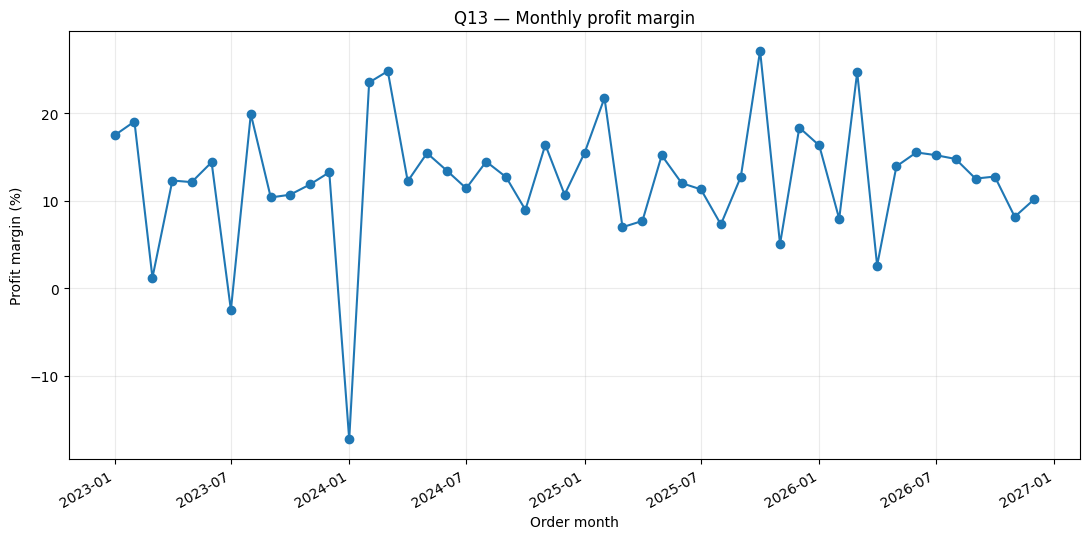

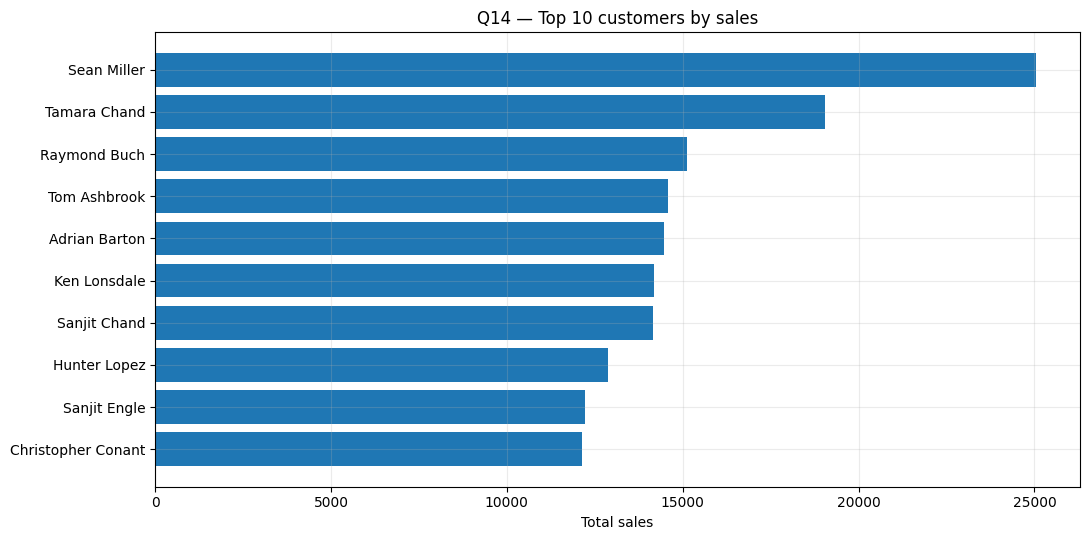

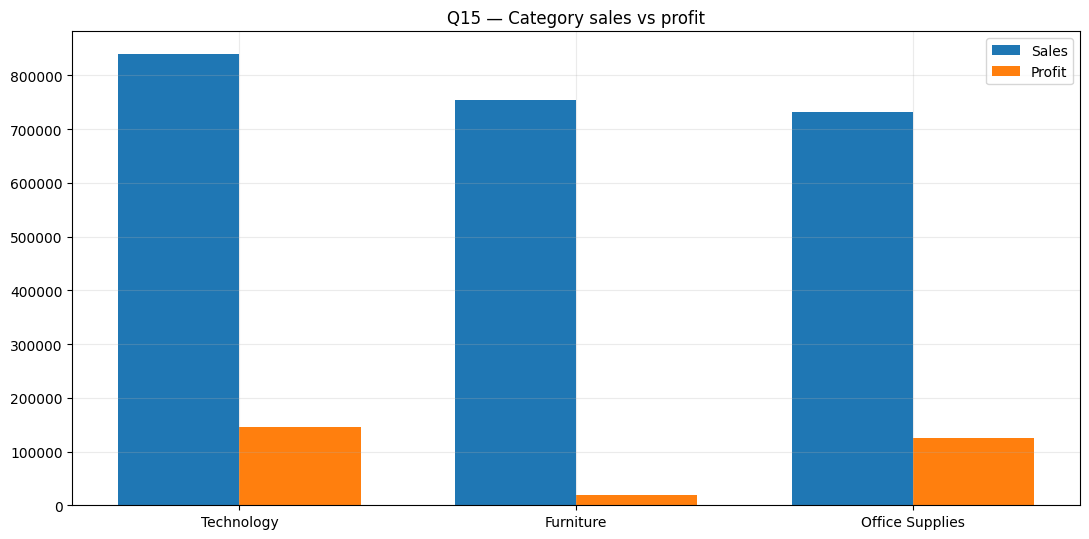

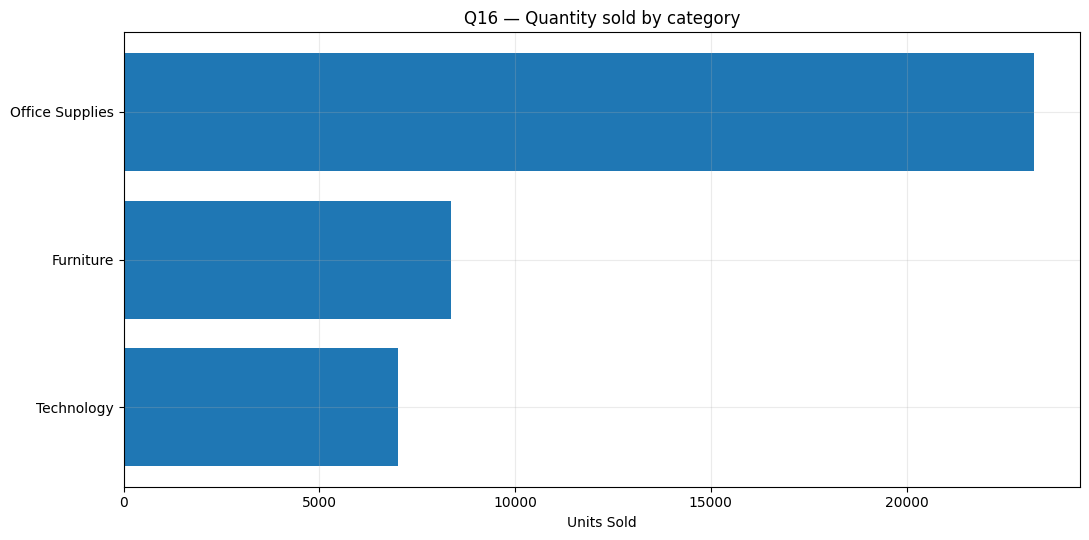

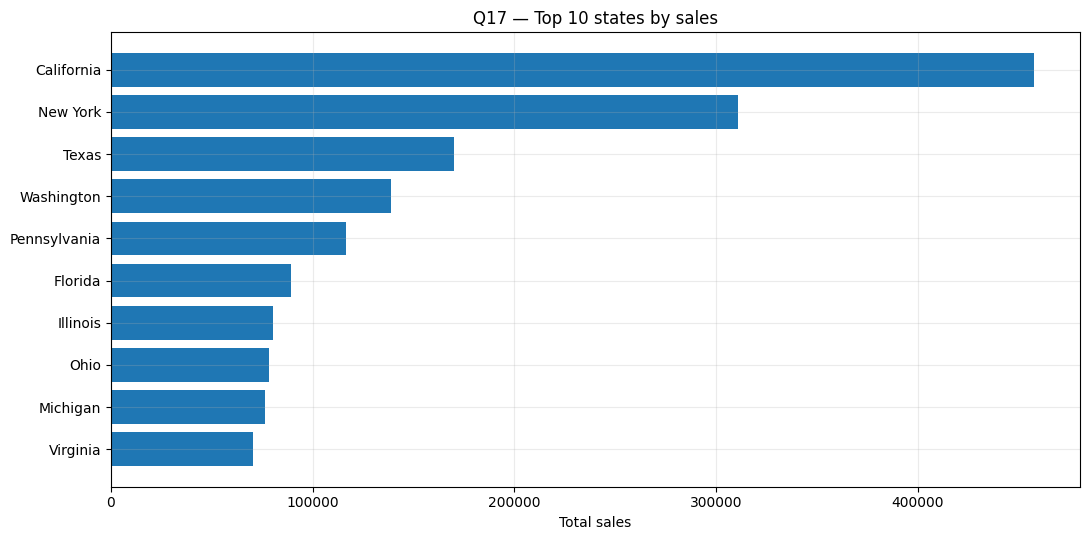

In [9]:
def plot_query(query_id, spec):
    title, sql, chart_type = spec
    df = query_results[query_id].copy()
    if df.empty:
        print(f"{query_id}: no data returned")
        return

    # Convert MySQL Decimal objects to numeric values where possible.
    for col in df.columns:
        if df[col].dtype == "object":
            try:
                df[col] = pd.to_numeric(df[col])
            except (ValueError, TypeError):
                pass

    fig, ax = plt.subplots(figsize=(11, 5.5))
    if chart_type == "kpi":
        row = df.iloc[0]
        metrics = ["total_sales", "total_profit", "distinct_orders", "distinct_customers", "units_sold"]
        values = [float(row[m]) for m in metrics]
        labels = ["Sales", "Profit", "Orders", "Customers", "Units"]
        bars = ax.bar(labels, values)
        ax.set_title(title)
        ax.set_ylabel("Value (mixed units; use table for exact values)")
        ax.ticklabel_format(axis="y", style="plain")
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{val:,.0f}", ha="center", va="bottom", fontsize=8)
    elif chart_type == "line_sales":
        df["order_month"] = pd.to_datetime(df["order_month"])
        ax.plot(df["order_month"], df["total_sales"], marker="o", label="Sales")
        ax.plot(df["order_month"], df["total_profit"], marker=".", label="Profit")
        ax.set_title(title); ax.set_xlabel("Order month"); ax.set_ylabel("Value"); ax.legend()
        fig.autofmt_xdate()
    elif chart_type == "line_margin":
        df["order_month"] = pd.to_datetime(df["order_month"])
        ax.plot(df["order_month"], df["profit_margin"] * 100, marker="o")
        ax.set_title(title); ax.set_xlabel("Order month"); ax.set_ylabel("Profit margin (%)")
        fig.autofmt_xdate()
    elif chart_type in ("bar_sales", "bar_profit", "bar_quantity", "bar_rate"):
        x = df.columns[0]
        if chart_type == "bar_sales":
            y = "total_sales"
        elif chart_type == "bar_profit":
            y = "total_profit"
        elif chart_type == "bar_quantity":
            y = "units_sold"
        else:
            y = "returned_order_rate"
        df[y] = pd.to_numeric(df[y])
        df = df.sort_values(y, ascending=True)
        ax.barh(df[x].astype(str), df[y])
        ax.set_title(title); ax.set_xlabel(y.replace("_", " ").title())
    elif chart_type == "bar_product_profit":
        label_col = "product_name"
        df["total_profit"] = pd.to_numeric(df["total_profit"])
        df = df.sort_values("total_profit", ascending=True)
        ax.barh(df[label_col].astype(str).str.slice(0, 48), df["total_profit"])
        ax.set_title(title); ax.set_xlabel("Total profit")
    elif chart_type == "bar_customer":
        df["total_sales"] = pd.to_numeric(df["total_sales"])
        df = df.sort_values("total_sales", ascending=True)
        ax.barh(df["customer_name"].astype(str), df["total_sales"])
        ax.set_title(title); ax.set_xlabel("Total sales")
    elif chart_type == "hist_ship":
        df["ship_days"] = pd.to_numeric(df["ship_days"])
        df["transaction_lines"] = pd.to_numeric(df["transaction_lines"])
        ax.bar(df["ship_days"], df["transaction_lines"])
        ax.set_title(title); ax.set_xlabel("Calendar days from order to ship"); ax.set_ylabel("Transaction lines")
    elif chart_type == "grouped_category":
        x = np.arange(len(df))
        width = 0.36
        ax.bar(x - width/2, df["total_sales"], width, label="Sales")
        ax.bar(x + width/2, df["total_profit"], width, label="Profit")
        ax.set_xticks(x); ax.set_xticklabels(df["category"], rotation=0)
        ax.set_title(title); ax.legend()
    elif chart_type == "bar_state":
        df["total_sales"] = pd.to_numeric(df["total_sales"])
        df = df.sort_values("total_sales", ascending=True)
        ax.barh(df["state_province"].astype(str), df["total_sales"])
        ax.set_title(title); ax.set_xlabel("Total sales")
    else:
        ax.text(0.5, 0.5, "No chart rule defined", ha="center", va="center")
        ax.set_axis_off()

    fig.tight_layout()
    plt.show()

for query_id, spec in QUERIES.items():
    plot_query(query_id, spec)


## 7. Save every query result as CSV

These CSVs can be reviewed, shared, or used as a controlled input to Power BI. Keep a note of the query/filter logic so metrics remain consistent across tools.

In [10]:
from pathlib import Path

OUTPUT_DIR = Path("../outputs/query_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for query_id, result_df in query_results.items():
    result_df.to_csv(OUTPUT_DIR / f"{query_id.lower()}_result.csv", index=False)

print(f"Exported {len(query_results)} query-result CSV files to {OUTPUT_DIR.resolve()}")


Exported 17 query-result CSV files to C:\Users\dell\OneDrive\Desktop\Companies Applied\Finance & Analytics\Project\Superstore_SQL_Python_Project\outputs\query_results


## 8. Business interpretation prompts

Use your actual query outputs to answer:
1. Which category leads sales, and does it also lead profit?
2. Which sub-categories have negative aggregate profit?
3. Which region contributes the most sales? Does its profit margin also look strong?
4. Do higher discount bands coincide with weaker profit margins? Why is that not proof that discounts caused lower profit?
5. Which products have the strongest and weakest aggregate profit?
6. How does the order-level returned rate vary by region?
7. What would you investigate next before making a business recommendation?

**Interview rule:** explain the method, state the verified result from your output, interpret the business implication, and mention limitations. Do not memorize numbers without being able to reproduce them.

## 9. Close the connection

Run this cell when you have finished all queries and charts.

In [11]:
if "connection" in globals() and connection.is_connected():
    connection.close()
    print("MySQL connection closed.")


MySQL connection closed.
